# 20 · Análisis exploratorio: cambios relativos sobre `ACH_4_P3`

**Etapa 25 del plan.** Tomás Henseler propuso en su informe del 2026-11-07 agregar, para cada variable numérica, su cambio relativo contra uno y dos meses atrás. Agregados a `ACO`, en 201908, sumaron +3,11 M en la banda (15 de 20 semillas). Acá se prueban sobre la vigente, en el banco temporal.

Texto del informe:

> r1 = (actual - lag1) / (abs(actual) + abs(lag1))
> r2 = (actual - lag2) / (abs(actual) + abs(lag2))
> El resultado está entre -1 y 1. Dos ceros observados producen cero; si falta cualquiera de los valores, se conserva NaN.

**Pregunta:** ¿`ACH_4_P3` gana más dinero si se le agregan `r1` y `r2`?

| Configuración | Columnas | Qué agrega a `ACH_4` |
|---|---:|---|
| `ACH_4_P3` | 1.180 | Nada: es la referencia. Sus predicciones se leen del `15` |
| `ACH_4_R_P3` | 1.438 | `r1` y `r2` de 129 variables: 258 columnas. **Esta decide** |

Mismo banco temporal del `15`: para evaluar un mes, el modelo entrena con todos los meses desde 201903 hasta dos meses antes. Se evalúan 201906 a 201910, con 5 semillas, 296 árboles y `BAJA+2` pesando el triple.

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/19/` ni en los `resultados/03_*` a `19_*`:** solo los lee.

Ficha: `fichas/etapa_25_cambios_relativos.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_15 = Path('../exp/15')                          # solo se lee
EXP = Path('../exp/20')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
REFERENCIA = 'ACH_4_P3'                             # la vigente del 15: sus predicciones se leen de exp/15
PESO_B2 = 3
CONFIGS = {'ACH_4_R_P3': 'R'}                       # configuración: bloque que se agrega a ACH_4
DECIDE = 'ACH_4_R_P3'
CONTRASTES = [('ACH_4_R_P3', REFERENCIA)]
HIPOTESIS = {'ACH_4_R_P3': 'Los cambios relativos de Tomás (r1 y r2 de 129 variables) ganan más que ACH_4_P3'}
LAGS_R = [1, 2]
ENVIOS = [2_000, 3_000, 4_000, 5_000, 6_000, 8_000, 10_000]   # curva por cantidad de envíos, solo para informar
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180, 'R': 258}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[0123456789]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 56


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 1 s


## 3. Tablas de `ACH_4`

Las mismas columnas de `ACH_4` del `15`: 1.180, el baseline más la historia curada y los cuatro bloques del `14`.

**Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 24 s · memoria máxima 6.4 GB


## 4. Cambios relativos

El código de Tomás está en la rama `feat/historia-transformaciones` del repo (commit `0d47308`): `scripts/historia/transforms.py` (`numeric_variables` y `relative`) y `scripts/historia/exp_cambios_relativos.py`. Acá se reescribe igual, sin importarlo:

- **Las 129 variables:** las 152 menos 8 banderas, 5 estados, 8 fechas, la edad y la antigüedad. Es `MONTOS`, la lista que ya usan los notebooks; se compara con la lista de Tomás copiada de su código.
- **La fórmula:** `(actual − lag) / (|actual| + |lag|)`, en doble precisión. Dos ceros dan 0; si falta alguno, NaN.
- **Los lags** son los de la tabla: mes calendario exacto del mismo cliente, con los meses rotos en NaN, como en el código de Tomás.
- **Los nombres** son los de Tomás: `{variable}_rel_sim1` y `{variable}_rel_sim2`.

**Control 4:** con los datos cortados en el mes, las columnas de ese mes dan lo mismo, armadas por otro camino (directo desde las fotos, sin la tabla). **Control 6:** la fórmula a mano en 300 filas, el rango de −1 a 1, y dos ceros dan 0.

In [4]:
# La lista de Tomás, copiada de transforms.numeric_variables
_flags = {'active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
          'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones'}
_states = {'tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency'}
_dates = {f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')}
NUMERICAS_TOMAS = [v for v in VARIABLES if v not in _flags | _states | _dates | {'cliente_edad', 'cliente_antiguedad'}]
assert NUMERICAS_TOMAS == MONTOS and len(MONTOS) == 129


def relativo(a, b):
    """Cambio simétrico acotado en [-1, 1]; dos ceros observados dan cero; un faltante da NaN."""
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    den = np.abs(a) + np.abs(b)
    salida = np.full(a.shape, np.nan)
    valido = np.isfinite(a) & np.isfinite(b)
    salida[valido & (den == 0)] = 0.0
    np.divide(a - b, den, out=salida, where=valido & (den > 0))
    return salida


def bloque_r(F, columnas):
    """Las 258 columnas, desde los valores y los lags de la tabla."""
    ubic = {c: i for i, c in enumerate(columnas)}
    salida = np.empty((F.shape[0], len(MONTOS) * len(LAGS_R)), dtype=np.float32)
    nombres = []
    for k in LAGS_R:
        for v in MONTOS:
            for inicio in range(0, F.shape[0], 200_000):
                fb = slice(inicio, inicio + 200_000)
                salida[fb, len(nombres)] = relativo(F[fb, ubic[v]], F[fb, ubic[f'{v}_lag{k}']])
            nombres.append(f'{v}_rel_sim{k}')
    return salida, nombres


def bloque_r_directo(filas, X, indice, clave):
    """El mismo bloque por otro camino: busca las fotos de 1 y 2 meses antes en el dataset."""
    j = [VARIABLES.index(v) for v in MONTOS]
    actual = X[filas][:, j]
    partes = []
    for k in LAGS_R:
        p = indice.get_indexer(clave[filas] - k)
        previo = np.where((p >= 0)[:, None], X[np.maximum(p, 0)][:, j], np.nan)
        partes.append(relativo(actual, previo).astype(np.float32))
    return np.hstack(partes)


t0 = time.time()
BR = {'R': bloque_r(T['F'], T['columnas'])}
assert BR['R'][0].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES['R'])
assert not set(BR['R'][1]) & set(T['columnas'] + [c for b in CANDIDATAS for c in B[b][1]])
R_ = BR['R'][0]
assert np.nanmin(R_) >= -1 and np.nanmax(R_) <= 1

# Control 4: sin fuga, y por otro camino
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloque_r_directo(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta])
    assert np.array_equal(C, R_[T['mes_fila'] == corte], equal_nan=True), corte
    del C

# Control 6: fórmula a mano, fila por fila, con números de Python
col_r = {c: i for i, c in enumerate(BR['R'][1])}
rng = np.random.default_rng(SEMILLA_PRIMIGENIA + 20)
probar = list(MONTOS[:3]) + rng.choice(MONTOS[3:], size=5, replace=False).tolist()
serie = {v: pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE) for v in probar}
for i in rng.choice(len(T['filas']), size=300, replace=False):
    clave = CLAVE[T['filas'][i]]
    for v in probar:
        a = serie[v][clave]
        for k in LAGS_R:
            b = serie[v].get(clave - k, np.nan)
            if np.isnan(a) or np.isnan(b):
                esperado = None
            elif a == 0 and b == 0:
                esperado = 0.0
            else:
                esperado = (a - b) / (abs(a) + abs(b))
            valor = R_[i, col_r[f'{v}_rel_sim{k}']]
            if esperado is None:
                assert np.isnan(valor), (v, k, i, valor)
            else:
                np.testing.assert_allclose(valor, esperado, rtol=1e-6, atol=1e-7, err_msg=f'{v}_rel_sim{k}')
dos_ceros = (T['F'][:, T['columnas'].index('mpayroll')] == 0) & (T['F'][:, T['columnas'].index('mpayroll_lag1')] == 0)
assert dos_ceros.sum() > 0 and (R_[dos_ceros, col_r['mpayroll_rel_sim1']] == 0).all()
del serie
gc.collect()
faltan = np.isnan(R_).mean(axis=0)
print(f'Cambios relativos y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')
print(f'Faltantes por columna: mediana {100 * np.median(faltan):.1f} %, máximo {100 * faltan.max():.1f} %')

Cambios relativos y controles 4 y 6 OK en 12 s · memoria máxima 6.4 GB
Faltantes por columna: mediana 2.9 %, máximo 75.0 %


## 5. Ventanas y controles

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado.

**Control 5:** `ACH_4_P3` de 201906, con la primera semilla, da la predicción del `15`. Comprueba que este notebook entrena igual que el `15`: lo único que cambia en la configuración nueva son las columnas agregadas.

**Control 11:** la configuración tiene las 1.438 columnas, sin nombres repetidos, y las primeras 1.180 son las de `ACH_4`.

In [5]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
assert ARBOLES == 296
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}

ES_B2 = CLASE[T['filas']] == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}
ENTRENA = {m: [x for x in MESES_TABLA if x <= m - DISTANCIA] for m in MESES_EVALUADOS}
assert all(ENTRENA[m] and max(ENTRENA[m]) <= m - DISTANCIA for m in MESES_EVALUADOS)        # control 3


def ruta(config, mes, semilla, que='pred'):
    return EXP / que / config / str(mes) / f'{semilla}.npy'


def tabla_de(config, filas):
    k = ESPERADO_N_VARIABLES[BASE_CURADA]
    extra = [BR[CONFIGS[config]]] if config in CONFIGS else []
    X = np.hstack([T['F'][filas, :k]] + [B[b][0][filas] for b in CANDIDATAS] + [e[0][filas] for e in extra])
    return X, T['columnas'][:k] + [c for b in CANDIDATAS for c in B[b][1]] + [c for e in extra for c in e[1]]


def dataset(config, mes):
    entrena = np.isin(T['mes_fila'], ENTRENA[mes])
    X, columnas = tabla_de(config, entrena)
    clase = CLASE[T['filas'][entrena]]
    d = lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=columnas, params=BINS, free_raw_data=True).construct()
    d.set_weight(np.where(clase == 'BAJA+2', PESO_B2, 1).astype(np.float32))
    del X
    return d, columnas


def entrenar(dtrain, semilla):
    return lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=ARBOLES)


print(pd.DataFrame({'meses de entrenamiento': {m: f'{ENTRENA[m][0]}-{ENTRENA[m][-1] % 100:02d}' for m in MESES_EVALUADOS},
                    'filas': {m: int(np.isin(T['mes_fila'], ENTRENA[m]).sum()) for m in MESES_EVALUADOS}}).to_string())

# Control 11
base_cols = tabla_de(REFERENCIA, np.arange(2))[1]
assert len(base_cols) == len(set(base_cols)) == ESPERADO_N_VARIABLES[JUNTAS]
for c, b in CONFIGS.items():
    cols = tabla_de(c, np.arange(2))[1]
    assert len(cols) == len(set(cols)) == ESPERADO_N_VARIABLES[JUNTAS] + ESPERADO_N_VARIABLES[b], c
    assert cols[:ESPERADO_N_VARIABLES[JUNTAS]] == base_cols

# Control 5
ruta_control = EXP / 'control_5.txt'
if not ruta_control.exists():
    t0 = time.time()
    dtrain, _ = dataset(REFERENCIA, 201906)
    modelo = entrenar(dtrain, SEMILLAS[0])
    prob = modelo.predict(tabla_de(REFERENCIA, es_mes[201906])[0], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_15 / 'pred' / REFERENCIA / '201906' / f'{SEMILLAS[0]}.npy')), 'ACH_4_P3 no reproduce el 15'
    ruta_control.parent.mkdir(parents=True, exist_ok=True)
    ruta_control.write_text('ok\n')
    del dtrain, modelo, prob
    gc.collect()
    print(f'Control 5 OK en {time.time() - t0:.0f} s')
else:
    print('Control 5 ya hecho')
print('Controles 3 y 11 OK')

       meses de entrenamiento   filas
201906              201903-04  251738
201907              201903-05  378501
201908              201903-06  506871
201909              201903-07  636724
201910              201903-08  768499
Control 5 OK en 27 s
Controles 3 y 11 OK


## 6. Modelos

Un modelo por mes y semilla, con 296 árboles. La referencia no se entrena: se leen sus predicciones del `15`.

**Retomar:** cada predicción se guarda al terminar el modelo, junto con la importancia de cada columna (ganancia de los cortes).

**Control 7:** hay predicción para cada mes y semilla.

In [6]:
falta = lambda c, m, s: not ruta(c, m, s).exists()
print('Modelos pendientes:', sum(falta(c, m, s) for c in CONFIGS for m in MESES_EVALUADOS for s in SEMILLAS))
segundos = {}
COLUMNAS_DE = {}
for c in CONFIGS:
    COLUMNAS_DE[c] = tabla_de(c, np.arange(2))[1]
    for m in MESES_EVALUADOS:
        if not any(falta(c, m, s) for s in SEMILLAS):
            continue
        dtrain, columnas = dataset(c, m)
        X_mes = tabla_de(c, es_mes[m])[0]
        for s in SEMILLAS:
            if not falta(c, m, s):
                continue
            t0 = time.time()
            modelo = entrenar(dtrain, s)
            for que, valor in (('imp', modelo.feature_importance('gain').astype(np.float64)),
                               ('pred', modelo.predict(X_mes, num_threads=N_HILOS).astype(np.float32))):
                destino = ruta(c, m, s, que)
                assert destino.is_relative_to(EXP), destino
                destino.parent.mkdir(parents=True, exist_ok=True)
                np.save(destino, valor)
            segundos.setdefault(c, []).append(time.time() - t0)
        print(f'{c} · {m}: {len(columnas)} variables, {np.mean(segundos.get(c, [0])):.0f} s por modelo · memoria máxima {memoria_gb()} GB', flush=True)
        del dtrain, X_mes
        gc.collect()

TODAS_CONFIGS = [REFERENCIA, *CONFIGS]
leer = lambda c, m, s: np.load(EXP_15 / 'pred' / REFERENCIA / str(m) / f'{s}.npy') if c == REFERENCIA else np.load(ruta(c, m, s))
PUNTAJE = {(c, m): np.stack([leer(c, m, s) for s in SEMILLAS]) for c in TODAS_CONFIGS for m in MESES_EVALUADOS}
assert all(v.shape == (N_SEMILLAS, es_mes[k[1]].sum()) and not np.isnan(v).any() for k, v in PUNTAJE.items())   # control 7
print('Predicciones completas:', len(PUNTAJE), 'grupos de', N_SEMILLAS, 'semillas')

Modelos pendientes: 25
ACH_4_R_P3 · 201906: 1438 variables, 26 s por modelo · memoria máxima 6.4 GB
ACH_4_R_P3 · 201907: 1438 variables, 33 s por modelo · memoria máxima 6.4 GB
ACH_4_R_P3 · 201908: 1438 variables, 40 s por modelo · memoria máxima 6.4 GB
ACH_4_R_P3 · 201909: 1438 variables, 45 s por modelo · memoria máxima 6.4 GB
ACH_4_R_P3 · 201910: 1438 variables, 51 s por modelo · memoria máxima 6.4 GB
Predicciones completas: 10 grupos de 5 semillas


## 7. Comparación

**Medida:** ganancia en la banda de 3.000 a 6.000 envíos, para cada mes y semilla. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla, como en el `15`.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** un desvío común, estimado con las dos configuraciones.

El intervalo es la diferencia más o menos 1,96 errores totales.

**Además, sin decidir:** la diferencia por cantidad de envíos, y qué parte de la ganancia de los cortes se lleva el bloque nuevo.

In [7]:
B_MES = {(c, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[(c, m)]]) for c, m in PUNTAJE}
filas = [{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[(c, m)][i]), 6)}
         for c, m in PUNTAJE for i, s in enumerate(SEMILLAS)]
meses_tabla = pd.DataFrame(filas)
meses_tabla.to_csv(RESULTADOS / '20_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(config):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in MESES_EVALUADOS:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[(config, m)]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            aporte = PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
            np.add.at(v, POS_CLIENTE[idx[orden]], aporte)
    return v / (len(MESES_EVALUADOS) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


por_semilla = lambda c: np.mean([B_MES[(c, m)] for m in MESES_EVALUADOS], axis=0)
ensamble = lambda c: float(np.mean([banda(curva(PUNTAJE[(c, m)].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in MESES_EVALUADOS]))
APORTE = {c: por_cliente(c) for c in TODAS_CONFIGS}

filas = []
for j, (c, contra) in enumerate(CONTRASTES):
    d_cliente = APORTE[c] - APORTE[contra]
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(c).mean() - por_semilla(contra).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    desvio = np.sqrt((por_semilla(c).var(ddof=1) + por_semilla(contra).var(ddof=1)) / 2)
    e_s = desvio * np.sqrt(2 / N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    filas.append({'config': c, 'contra': contra, 'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s, 'error_total_M': e_t,
                  'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t, 'd_ensamble_M': ensamble(c) - ensamble(contra),
                  'semillas_a_favor': int((por_semilla(c) > por_semilla(contra)).sum()),
                  **{f'd_{m}': B_MES[(c, m)].mean() - B_MES[(contra, m)].mean() for m in MESES_EVALUADOS}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '20_comparacion.csv', index=False)

filas = []
for c, b in CONFIGS.items():
    nuevas = COLUMNAS_DE[c][ESPERADO_N_VARIABLES[JUNTAS]:]
    I = np.stack([np.load(ruta(c, m, s, 'imp')) for m in MESES_EVALUADOS for s in SEMILLAS])
    parte = I / I.sum(axis=1, keepdims=True)
    for k, n in enumerate(nuevas):
        filas.append({'config': c, 'variable': n, 'parte_ganancia': parte[:, ESPERADO_N_VARIABLES[JUNTAS] + k].mean()})
    print(f'{c}: el bloque nuevo ({len(nuevas)} columnas) se lleva el {100 * parte[:, ESPERADO_N_VARIABLES[JUNTAS]:].sum(axis=1).mean():.1f} % '
          f'de la ganancia de los cortes ({100 * len(nuevas) / len(COLUMNAS_DE[c]):.1f} % de las columnas)')
importancia = pd.DataFrame(filas).sort_values(['config', 'parte_ganancia'], ascending=[True, False])
importancia.round(6).to_csv(RESULTADOS / '20_importancia.csv', index=False)

print()
print('EXPLORATORIO')
print(comparacion.round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in MESES_EVALUADOS} for c in TODAS_CONFIGS}).T.round(2).to_string())
print()
print('AUC por mes (media de semillas):')
print(meses_tabla.groupby(['config', 'foto_mes'])['auc'].mean().unstack().loc[TODAS_CONFIGS].round(4).to_string())
print()
print(f'Las 10 columnas nuevas que más pesan en {DECIDE}:')
print(importancia[importancia.config == DECIDE].head(10).assign(parte_ganancia=lambda t: (100 * t.parte_ganancia).round(2)).to_string(index=False))

# Curva por cantidad de envíos: media de meses y semillas
CURVA = {c: np.mean([curva(p, ES_B2[es_mes[m]]) for m in MESES_EVALUADOS for p in PUNTAJE[(c, m)]], axis=0) / 1e6 for c in TODAS_CONFIGS}
por_envios = pd.DataFrame({c: {n: CURVA[c][n - 1] for n in ENVIOS} for c in TODAS_CONFIGS}).T
print()
print('Ganancia por cantidad de envíos (M, media de meses y semillas):')
print(por_envios.round(2).to_string())
print('Diferencia contra la referencia:', {n: round(por_envios.loc[DECIDE, n] - por_envios.loc[REFERENCIA, n], 2) for n in ENVIOS})

ACH_4_R_P3: el bloque nuevo (258 columnas) se lleva el 6.5 % de la ganancia de los cortes (17.9 % de las columnas)

EXPLORATORIO
    config   contra  d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  semillas_a_favor  d_201906  d_201907  d_201908  d_201909  d_201910
ACH_4_R_P3 ACH_4_P3 0.64              0.65             0.44           0.78       -0.89        2.17          0.94                 4      1.81     -1.96      1.34      3.07     -1.05

Ganancia en la banda por mes (M, media de semillas):
            201906  201907  201908  201909  201910
ACH_4_P3    244.86  297.34  211.50  259.83  293.14
ACH_4_R_P3  246.67  295.37  212.84  262.91  292.09

AUC por mes (media de semillas):
foto_mes    201906  201907  201908  201909  201910
config                                            
ACH_4_P3    0.9205  0.9091  0.9106  0.9180  0.9281
ACH_4_R_P3  0.9192  0.9098  0.9102  0.9178  0.9269

Las 10 columnas nuevas que más pesan en ACH_4_R_P3:
    config 

## 8. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

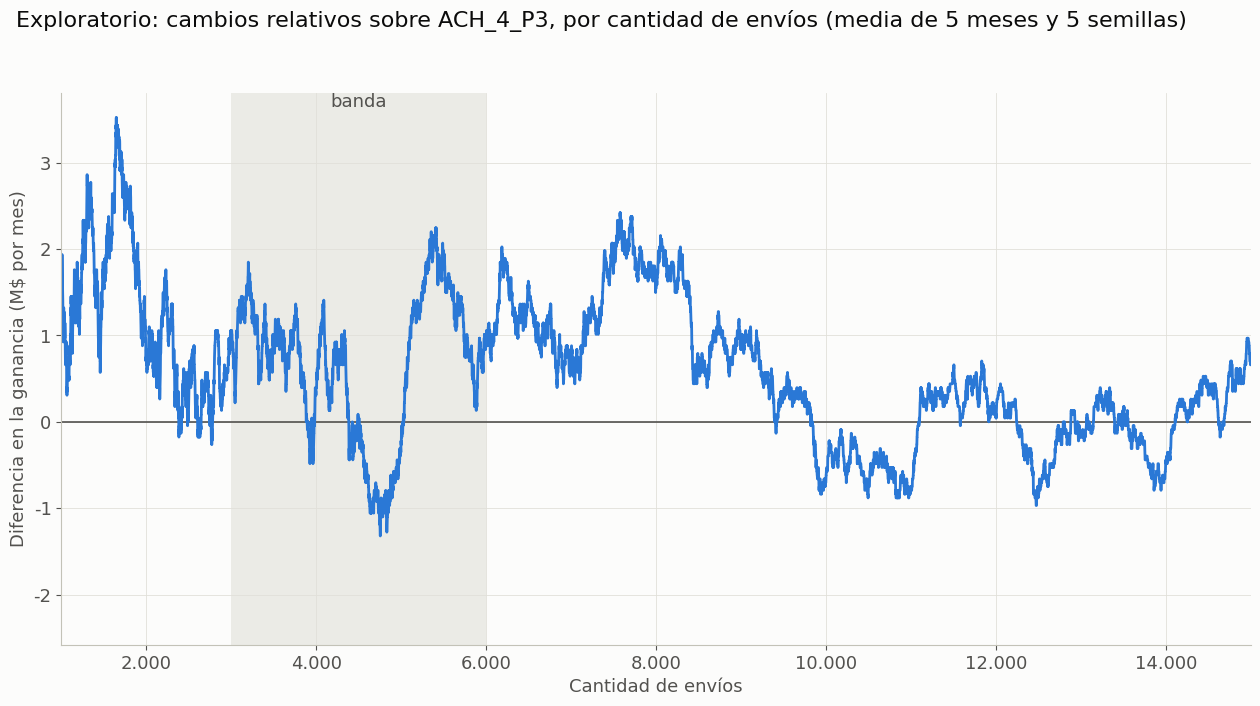

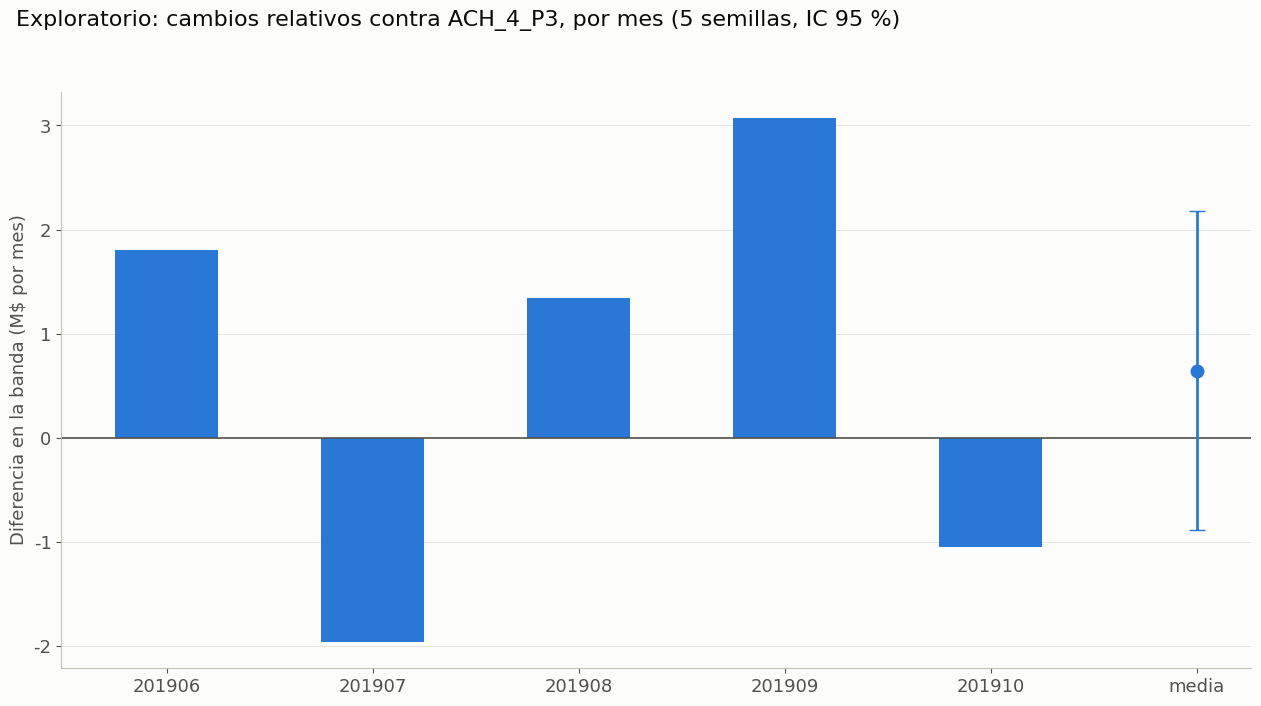

In [8]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


r = comparacion.iloc[0]
formato = FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1))

fig, ax = plt.subplots(figsize=TAMANO)
dif = CURVA[DECIDE] - CURVA[REFERENCIA]
n = np.arange(1, len(dif) + 1)
ax.axhline(0, color=TINTA_2, lw=1.2)
ax.axvspan(BANDA[0], BANDA[1], color=GRILLA, alpha=0.6, lw=0)
ax.plot(n, dif, color=AZUL, lw=2)
ax.text((BANDA[0] + BANDA[1]) / 2, ax.get_ylim()[1], 'banda', ha='center', va='top', color=TINTA_2)
ax.set_xlim(1_000, 15_000)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: coma(v, 0)))
ax.yaxis.set_major_formatter(formato)
ax.set_xlabel('Cantidad de envíos')
ax.set_ylabel('Diferencia en la ganancia (M$ por mes)')
fig.suptitle('Exploratorio: cambios relativos sobre ACH_4_P3, por cantidad de envíos (media de 5 meses y 5 semillas)',
             x=0.02, ha='left', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '20_1_cambios_relativos.png', dpi=DPI)
plt.show()

fig, ax = plt.subplots(figsize=TAMANO)
ax.axhline(0, color=TINTA_2, lw=1.2)
x = [str(m) for m in MESES_EVALUADOS] + ['media']
ax.bar(x[:-1], [r[f'd_{m}'] for m in MESES_EVALUADOS], color=AZUL, width=0.5)
ax.errorbar([x[-1]], [r.d_M], yerr=[[r.d_M - r.ic95_inf_M], [r.ic95_sup_M - r.d_M]], fmt='o', color=AZUL, ms=9, capsize=6, lw=2)
ax.yaxis.set_major_formatter(formato)
ax.set_ylabel('Diferencia en la banda (M$ por mes)')
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
fig.suptitle('Exploratorio: cambios relativos contra ACH_4_P3, por mes (5 semillas, IC 95 %)', x=0.02, ha='left', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '20_2_por_mes.png', dpi=DPI)
plt.show()

## 9. Lectura fijada antes de correr

Decide `ACH_4_R_P3` contra `ACH_4_P3`, con `d` = la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: `ACH_4_R_P3` pasa a ser la vigente |
| Entre −1 y +1 M | Empate: queda `ACH_4_P3`, que es más simple |
| −1 M o menos | Resta: queda `ACH_4_P3` |

El intervalo se informa siempre. 201908 no es un mes limpio para esta estrategia: Tomás la evaluó y la eligió en ese mes.

**Control 8:** las salidas anteriores no cambiaron.

In [9]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
for r in comparacion.itertuples():
    marca = ' · DECIDE' if (r.config, r.contra) == (DECIDE, REFERENCIA) else ''
    print(f'{r.config} contra {r.contra}: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M · '
          f'ensamble {r.d_ensamble_M:+.2f} M · semillas a favor {r.semillas_a_favor} de {N_SEMILLAS} · {lectura(r.d_M)}{marca}')

t = comparacion.set_index(['config', 'contra'])
pd.DataFrame([{'config': c, 'hipotesis': HIPOTESIS[c], 'contra': REFERENCIA, 'columnas': len(COLUMNAS_DE[c]),
               'd_M': round(t.loc[(c, REFERENCIA), 'd_M'], 3), 'resultado': lectura(t.loc[(c, REFERENCIA), 'd_M']),
               'decide': c == DECIDE} for c in CONFIGS]).to_csv(RESULTADOS / '20_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 23.1 min en total · memoria máxima 6.4 GB
Segundos por modelo: {'ACH_4_R_P3': 50.5}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

ACH_4_R_P3 contra ACH_4_P3: +0.64 M (-0.89 a 2.17) · error 0.78 M · ensamble +0.94 M · semillas a favor 4 de 5 · Empate · DECIDE
